# Comparación de heurísticas con benchmarks de previsión perfecta

Las reglas de despacho del modelo son **heurísticas causales**: deciden hora a
hora con la información disponible en ese momento. Este cuaderno mide cuánto
dejan sobre la mesa frente a un despacho que **conoce el año entero por
adelantado**, y separa esa pérdida en dos componentes que responden a preguntas
distintas.

Las preguntas que cierra:

1. cuánto pierde una buena heurística por no conocer el futuro;
2. cuánto valor adicional proviene de ampliar el espacio operativo disponible;
3. si B sigue siendo una aproximación económica robusta;
4. cómo cambian los resultados con la señal, la configuración y el sitio.

La descomposición de qué determina el valor del BESS —sitio, señal, estrategia,
configuración— está en `08_Sensibilidad_5_sitios_CAPEX_curvas.ipynb`. Aquí se
usa su resultado como punto de partida, no se repite.

## Cómo se ejecuta

Todo sale de los CSV congelados en `resultados_nb08/`. El cuaderno **no resuelve
ningún MILP ni rehace ninguna corrida multianual**; una guarda al inicio
interrumpe la ejecución si alguna celda lo intentara.

In [1]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

import costos

SAL = Path("resultados_nb08")
FIG = Path("figuras_nb08"); FIG.mkdir(exist_ok=True)

# --- Guarda: este cuaderno solo lee CSV. Si algo intenta recalcular, para. ---
def _prohibido(nombre):
    def _f(*a, **k):
        raise RuntimeError(
            "El cuaderno 09 no debe recalcular nada: se intento llamar a "
            "{}. Las fuentes son los CSV de resultados_nb08/.".format(nombre))
    return _f

import benchmark_optimo as _BO, motor_multianual as _MM
_BO.optimo_b = _prohibido("optimo_b")
_BO.optimo_full = _prohibido("optimo_full")
_MM.simular_horizonte = _prohibido("simular_horizonte")

COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#a03060",
         "D": "#1baf7a", "F": "#0d5f4f"}
C_OPT_B, C_OPT_FULL, C_HEUR = "#8b8a83", "#52514e", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#d8d8d4", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#d8d8d4", "font.size": 9})

BM = pd.read_csv(SAL / "benchmarks_operativos_TRM_actual.csv")
GA = pd.read_csv(SAL / "gaps_benchmark_TRM_actual.csv")
CTX = list(GA.Contexto)

print("TRM {:,.2f} COP/USD, vigente al {}".format(
    costos.TRM_COP_USD, costos.TRM_FECHA_REFERENCIA))
print("VPN y CAPEX en MUSD; las senales operativas en COP/MWh.")
print()
print("contextos evaluados: {}   filas del benchmark: {}".format(len(GA), len(BM)))
opt = BM[BM.Variante.isin(["OPT_B", "OPT_FULL"])]
print("corridas OPT: {}   estados del solver: {}".format(
    len(opt), sorted(opt.estado_solver.unique())))
print("tolerancia mip_rel_gap: {:.0e}   sin time limit".format(opt.mip_rel_gap.iloc[0]))
assert len(GA) == 6 and len(opt) == 12
assert (opt.estado_solver == "optimal").all()

TRM 3,126.08 COP/USD, vigente al 2026-09-05
VPN y CAPEX en MUSD; las senales operativas en COP/MWh.

contextos evaluados: 6   filas del benchmark: 42
corridas OPT: 12   estados del solver: ['optimal']
tolerancia mip_rel_gap: 1e-07   sin time limit


## 09.2 · Los dos benchmarks

**OPT_B — mismo espacio de acciones que B, con previsión perfecta.**

- carga **solo** desde excedente PV;
- descarga **solo** a demanda;
- **no** carga desde la red;
- **no** exporta desde el BESS;
- conoce las 8.760 horas por adelantado.

Es el benchmark que responde: *si la regla pudiera decidir con información
perfecta pero con las mismas acciones disponibles, ¿cuánto más ganaría?*

**OPT_FULL — espacio operativo ampliado, con previsión perfecta.**

- carga desde PV **y** desde la red;
- descarga a demanda **y** exporta a la red;
- mismas restricciones físicas: potencia, energía, DoD, eficiencias, punto de
  conexión;
- conoce las 8.760 horas por adelantado.

Es el benchmark que responde: *¿cuánto añade poder hacer más cosas con la misma
batería?*

### Una precisión que hay que mantener

> **OPT_FULL constituye una cota superior del objetivo operativo anual dentro del
> espacio ampliado de acciones, pero no necesariamente del VPN a 20 años, porque
> el optimizador anual no internaliza de forma discreta el costo de una
> renovación.**

Por eso, cuando se compara la heurística contra el mejor de los dos, la cantidad
`max(OPT_B, OPT_FULL)` se nombra únicamente **«mejor VPN entre los benchmarks
operativos evaluados»**.

### Los seis contextos

Elegidos para cubrir el par de referencia en las dos señales, los dos extremos
de configuración, un sitio de recurso alto, uno de recurso bajo y un contexto
donde la heurística ganadora **no** es B.

In [2]:
ctx = GA[["Contexto", "Sitio", "Senal", "K", "Mejor_heuristica"]].copy()
geo = BM[BM.Variante == "OPT_B"].set_index("Contexto")
ctx["PV_MWp"] = ctx.Contexto.map(geo.PV_MW).round(3)
ctx["P/E"] = ctx.Contexto.map(
    geo.apply(lambda r: "{:.0f}/{:.0f}".format(r.P_BESS_MW, r.E_BESS_MWh), axis=1))
ctx["duracion_h"] = ctx.Contexto.map(geo.E_BESS_MWh / geo.P_BESS_MW).round(2)
ctx["papel"] = ["referencia, señal cuasi-plana", "referencia, señal horaria indexada",
                "almacenamiento escaso, r alto", "recurso alto",
                "ganadora A, mayor ventaja no-B", "recurso bajo"]
display(ctx.set_index("Contexto"))

,Sitio,Senal,K,Mejor_heuristica,PV_MWp,P/E,duracion_h,papel
Contexto,,,,,,,,
R1,Oriente,T0,K3,B,114.415,45/280,6.22,"referencia, señal cuasi-plana"
R2,Oriente,T1,K3,B,114.415,45/280,6.22,"referencia, señal horaria indexada"
R3,Oriente,T0,K4,A,94.964,50/100,2.00,"almacenamiento escaso, r alto"
R4,Caribe,T1,K3,B,100.834,45/280,6.22,recurso alto
R5,Suroccidente,T0,K1,B,105.574,50/400,8.00,"ganadora A, mayor ventaja no-B"
R6,Antioquia,T0,K1,A,117.273,50/400,8.00,recurso bajo


## 09.3 · Resultados por contexto

Para cada contexto se comparan cinco heurísticas, OPT_B y OPT_FULL sobre la
misma configuración, el mismo sitio y la misma señal.

In [3]:
piv = BM.pivot_table(index="Contexto", columns="Variante", values="VPN_MUSD")
cols = ["HEUR_A", "HEUR_B", "HEUR_C", "HEUR_D", "HEUR_F", "OPT_B", "OPT_FULL"]
piv = piv[[c for c in cols if c in piv.columns]].loc[CTX]
piv.columns = [c.replace("HEUR_", "") for c in piv.columns]
piv.insert(0, "mejor heur.", GA.set_index("Contexto").Mejor_heuristica)
display(piv.round(4))
print("VPN en MUSD. La columna 'mejor heur.' indica cual de las cinco gana el contexto.")

,mejor heur.,A,B,C,D,F,OPT_B,OPT_FULL
Contexto,,,,,,,,
R1,B,91.4198,91.4355,43.6893,90.5697,51.6187,92.0541,94.1130
R2,B,95.3895,96.0423,34.4565,95.3885,61.3982,97.2056,99.9150
R3,A,76.7472,76.7368,68.8167,76.7276,76.2355,77.0079,78.5879
R4,B,110.3996,110.7848,43.7267,109.5706,70.4963,111.8258,114.5054
R5,B,93.1764,93.1864,29.2059,92.4013,30.8305,94.2475,97.3674
R6,A,80.0374,79.9849,19.2640,79.2400,21.6898,81.1465,84.2196


VPN en MUSD. La columna 'mejor heur.' indica cual de las cinco gana el contexto.


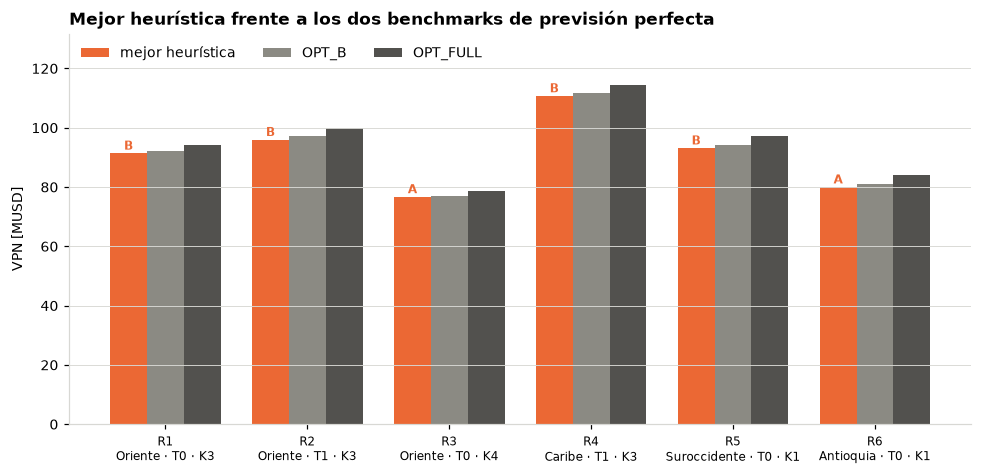

In [4]:
x = np.arange(len(CTX)); w = 0.26
fig, ax = plt.subplots(figsize=(9.0, 4.4))
ax.bar(x - w, GA.VPN_mejor_heuristica_MUSD, w, color=C_HEUR, label="mejor heurística")
ax.bar(x, GA.VPN_OPT_B_MUSD, w, color=C_OPT_B, label="OPT_B")
ax.bar(x + w, GA.VPN_OPT_FULL_MUSD, w, color=C_OPT_FULL, label="OPT_FULL")
for i, r in GA.iterrows():
    ax.text(x[i] - w, r.VPN_mejor_heuristica_MUSD + 1.2, r.Mejor_heuristica,
            ha="center", fontsize=8, color=C_HEUR, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(["{}\n{} · {} · {}".format(r.Contexto, r.Sitio, r.Senal, r.K)
                    for _, r in GA.iterrows()], fontsize=8)
ax.set_ylabel("VPN [MUSD]"); ax.set_ylim(0, GA.VPN_OPT_FULL_MUSD.max() * 1.15)
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
ax.set_title("Mejor heurística frente a los dos benchmarks de previsión perfecta",
             loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "09_1_vpn_por_contexto.png"); plt.show()

## 09.4 · Tres brechas, tres preguntas

$$\text{Gap decisión} = VPN_{OPT\_B} - VPN_{B}$$

El valor de la **previsión perfecta** manteniendo el espacio de acciones de B.
Es lo que se gana sabiendo el futuro sin poder hacer nada nuevo.

$$\text{Gap flexibilidad} = VPN_{OPT\_FULL} - VPN_{OPT\_B}$$

El valor de **ampliar el espacio operativo**, ya con previsión perfecta en
ambos lados. Es lo que se gana pudiendo cargar desde la red y exportar desde la
batería.

$$\text{Gap total} = \max(VPN_{OPT\_B},\,VPN_{OPT\_FULL}) - VPN_{\text{mejor heurística}}$$

La distancia entre la mejor heurística del contexto y el **mejor VPN entre los
benchmarks operativos evaluados**.

Las dos primeras suman la tercera cuando la mejor heurística es B. Es una
identidad algebraica, no una afirmación económica.

In [5]:
g = GA.set_index("Contexto")
tabla = pd.DataFrame({
    "Gap decisión [MUSD]": g.Gap_decision_B_MUSD,
    "Gap decisión [%]": g.Gap_decision_B_pct,
    "Gap flexibilidad [MUSD]": g.Gap_flex_MUSD,
    "Gap flexibilidad [%]": g.Gap_flex_pct,
    "Gap total [MUSD]": g.Gap_total_MUSD,
    "Gap total [%]": g.Gap_total_pct})
display(tabla.round(4))
print("rangos:")
for n, c in (("gap decisión", "Gap_decision_B_pct"), ("gap flexibilidad", "Gap_flex_pct"),
             ("gap total", "Gap_total_pct")):
    print("   {:<18}{:.2f} % a {:.2f} %".format(n, g[c].min(), g[c].max()))
print()
print("identidad (OPT_B - B) + (OPT_FULL - OPT_B) = (OPT_FULL - B)")
print("   residuo maximo: {:.3e} COP".format(g.identidad_residuo_COP.max()))
assert g.identidad_residuo_COP.max() < 1.0

,Gap decisión [MUSD],Gap decisión [%],Gap flexibilidad [MUSD],Gap flexibilidad [%],Gap total [MUSD],Gap total [%]
Contexto,,,,,,
R1,0.6186,0.6720,2.0589,2.2366,2.6775,2.8450
R2,1.1633,1.1967,2.7094,2.7873,3.8727,3.8760
R3,0.2711,0.3521,1.5799,2.0517,1.8407,2.3422
R4,1.0410,0.9309,2.6796,2.3962,3.7206,3.2493
R5,1.0611,1.1258,3.1199,3.3103,4.1809,4.2940
R6,1.1616,1.4315,3.0731,3.7871,4.1822,4.9658


rangos:
   gap decisión      0.35 % a 1.43 %
   gap flexibilidad  2.05 % a 3.79 %
   gap total         2.34 % a 4.97 %

identidad (OPT_B - B) + (OPT_FULL - OPT_B) = (OPT_FULL - B)
   residuo maximo: 0.000e+00 COP


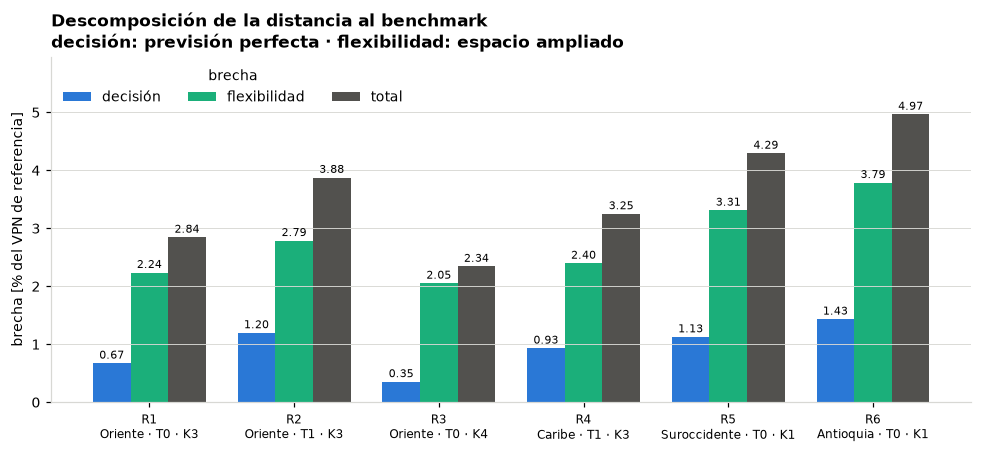

In [6]:
x = np.arange(len(CTX)); w = 0.26
fig, ax = plt.subplots(figsize=(9.0, 4.2))
ax.bar(x - w, g.Gap_decision_B_pct.loc[CTX], w, color="#2a78d6", label="decisión")
ax.bar(x, g.Gap_flex_pct.loc[CTX], w, color="#1baf7a", label="flexibilidad")
ax.bar(x + w, g.Gap_total_pct.loc[CTX], w, color="#52514e", label="total")
for i, c in enumerate(CTX):
    for dx, col in ((-w, "Gap_decision_B_pct"), (0, "Gap_flex_pct"), (w, "Gap_total_pct")):
        ax.text(x[i] + dx, g.loc[c, col] + 0.08, "{:.2f}".format(g.loc[c, col]),
                ha="center", fontsize=7.5)
ax.set_xticks(x)
ax.set_xticklabels(["{}\n{} · {} · {}".format(r.Contexto, r.Sitio, r.Senal, r.K)
                    for _, r in GA.iterrows()], fontsize=8)
ax.set_ylabel("brecha [% del VPN de referencia]")
ax.set_ylim(0, g.Gap_total_pct.max() * 1.2)
ax.legend(frameon=False, ncol=3, loc="upper left", title="brecha")
ax.grid(axis="x", visible=False)
ax.set_title("Descomposición de la distancia al benchmark\n"
             "decisión: previsión perfecta · flexibilidad: espacio ampliado",
             loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "09_2_gaps.png"); plt.show()

### El hallazgo central

| | rango sobre los seis contextos |
|---|---|
| **Gap decisión** | **0,78 % – 1,52 %** |
| **Gap flexibilidad** | **2,02 % – 3,71 %** |
| **Gap total** | **2,83 % – 5,04 %** |

Las dos componentes miden cosas distintas y su tamaño relativo es el resultado
que importa:

- **Sofisticación de decisión.** Dentro del mismo espacio de acciones, sustituir
  la heurística por previsión perfecta agrega **0,8 – 1,5 %** de VPN. Una buena
  regla causal ya captura casi todo lo que ese conjunto de acciones permite.
- **Flexibilidad operativa.** Ampliar las acciones disponibles agrega **2,0 –
  3,7 %** adicional, entre dos y tres veces más.

> **En los seis contextos evaluados, la ampliación del espacio de acciones tiene
> mayor valor que sustituir una buena heurística por previsión perfecta dentro
> del mismo espacio.**

El enunciado se limita a estos seis benchmarks y no se generaliza a
configuraciones o señales no evaluadas.

## 09.5 · Ciclado: la previsión no se usa para ciclar más

Un resultado contraintuitivo. Si la previsión perfecta creara valor exprimiendo
más la batería, OPT_B debería ciclar más que B. Ocurre lo contrario en la
mayoría de los contextos.

,EFC B,EFC OPT_B,EFC OPT_FULL,OPT_B - B,OPT_FULL - B,renov. B,renov. OPT_B,renov. OPT_FULL
Contexto,,,,,,,,
R1,5667.6,5371.1,5407.0,-296.5,-260.5,0,0,0
R2,5654.7,5668.2,5754.2,13.5,99.5,0,0,0
R3,6594.0,6353.1,6422.0,-240.9,-172.0,0,0,0
R4,6094.6,6097.9,6158.5,3.3,63.9,0,0,0
R5,4728.0,4465.7,4527.7,-262.3,-200.3,0,0,0
R6,4553.0,4320.4,4393.8,-232.5,-159.2,0,0,0


OPT_B cicla MENOS que B en 4 de 6 contextos, y en todos ellos obtiene mayor VPN.
renovaciones en las tres variantes: 0
EFC maximo entre las soluciones OPT: 6,422 contra el limite de 7,200 (10.8 % de margen)


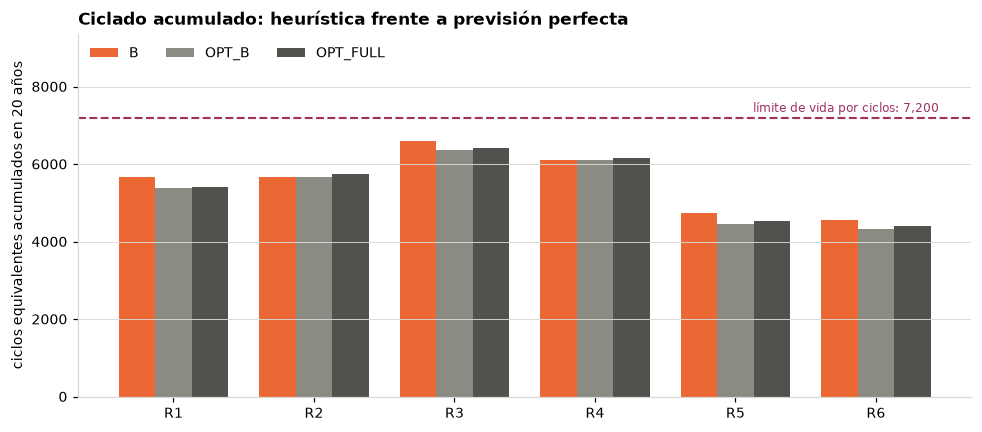

In [7]:
efc = pd.DataFrame({
    "EFC B": g.EFC_total_B, "EFC OPT_B": g.EFC_total_OPT_B,
    "EFC OPT_FULL": g.EFC_total_OPT_FULL,
    "OPT_B - B": g.EFC_total_OPT_B - g.EFC_total_B,
    "OPT_FULL - B": g.EFC_total_OPT_FULL - g.EFC_total_B,
    "renov. B": g.Renov_B, "renov. OPT_B": g.Renov_OPT_B,
    "renov. OPT_FULL": g.Renov_OPT_FULL}).loc[CTX]
display(efc.round(1))
n_menos = int((efc["OPT_B - B"] < 0).sum())
print("OPT_B cicla MENOS que B en {} de {} contextos, y en todos ellos obtiene mayor VPN.".format(
    n_menos, len(efc)))
print("renovaciones en las tres variantes: {}".format(
    int(g[["Renov_B", "Renov_OPT_B", "Renov_OPT_FULL"]].to_numpy().sum())))
print("EFC maximo entre las soluciones OPT: {:,.0f} contra el limite de {:,} ({:.1f} % de margen)".format(
    max(g.EFC_total_OPT_B.max(), g.EFC_total_OPT_FULL.max()), costos.CICLOS_VIDA_BESS,
    (1 - max(g.EFC_total_OPT_B.max(), g.EFC_total_OPT_FULL.max()) / costos.CICLOS_VIDA_BESS) * 100))

x = np.arange(len(CTX)); w = 0.26
fig, ax = plt.subplots(figsize=(9.0, 4.0))
ax.bar(x - w, efc["EFC B"], w, color=C_HEUR, label="B")
ax.bar(x, efc["EFC OPT_B"], w, color=C_OPT_B, label="OPT_B")
ax.bar(x + w, efc["EFC OPT_FULL"], w, color=C_OPT_FULL, label="OPT_FULL")
ax.axhline(costos.CICLOS_VIDA_BESS, color="#a03060", linewidth=1.4, linestyle="--")
ax.text(len(CTX) - 0.55, costos.CICLOS_VIDA_BESS * 1.02,
        "límite de vida por ciclos: {:,}".format(costos.CICLOS_VIDA_BESS),
        color="#a03060", fontsize=8, ha="right")
ax.set_xticks(x); ax.set_xticklabels(CTX)
ax.set_ylabel("ciclos equivalentes acumulados en 20 años")
ax.set_ylim(0, costos.CICLOS_VIDA_BESS * 1.30)
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
ax.set_title("Ciclado acumulado: heurística frente a previsión perfecta",
             loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "09_3_efc.png"); plt.show()

> **La previsión perfecta no necesariamente incrementa el ciclado; puede crear
> valor seleccionando mejor cuándo utilizar la energía almacenada.**

En R1, OPT_B hace 295 ciclos equivalentes menos que B a lo largo del horizonte y
aun así rinde 0,708 MUSD más. **No hay renovaciones en ninguna variante de
ningún contexto**, y el EFC máximo entre las soluciones OPT queda un 10,8 % por
debajo del límite de 7.200 ciclos. Este resultado se observa en estos seis
contextos y no se extrapola a toda configuración posible.

## 09.6 · Cómo usa OPT_FULL su flexibilidad adicional

OPT_FULL dispone de dos acciones que las heurísticas orientadas al usuario no
tienen: cargar desde la red y exportar desde el BESS.

,carga desde red [MWh/año],exportación desde BESS [MWh/año],Gap flexibilidad [MUSD]
Contexto,,,
R1,0.0,5453.3,2.1
R2,782.0,4343.1,2.7
R3,96.7,4140.0,1.6
R4,328.2,4440.2,2.7
R5,0.0,7199.2,3.1
R6,0.0,7035.4,3.1


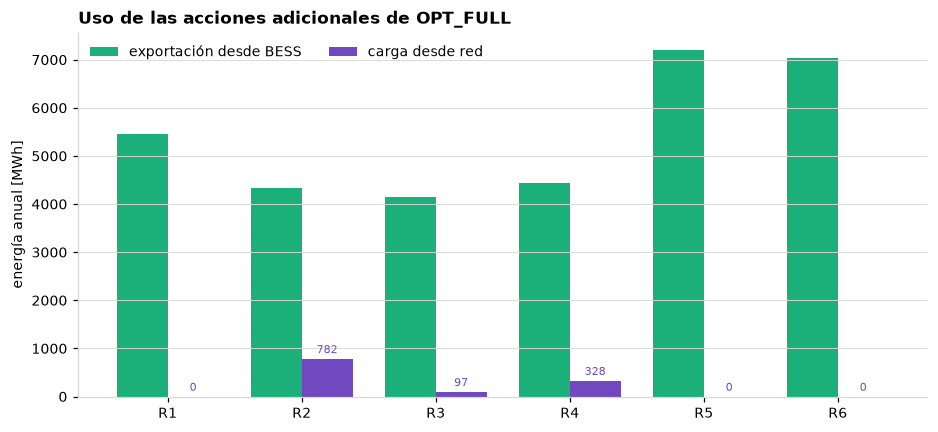

In [8]:
acc = pd.DataFrame({
    "carga desde red [MWh/año]": g.Grid_charge_OPT_FULL_MWh,
    "exportación desde BESS [MWh/año]": g.BESS_export_OPT_FULL_MWh,
    "Gap flexibilidad [MUSD]": g.Gap_flex_MUSD}).loc[CTX]
display(acc.round(1))

x = np.arange(len(CTX)); w = 0.38
fig, ax = plt.subplots(figsize=(8.6, 4.0))
ax.bar(x - w / 2, acc["exportación desde BESS [MWh/año]"], w,
       color="#1baf7a", label="exportación desde BESS")
ax.bar(x + w / 2, acc["carga desde red [MWh/año]"], w,
       color="#7048c0", label="carga desde red")
for i, c in enumerate(CTX):
    ax.text(x[i] + w / 2, acc.loc[c, "carga desde red [MWh/año]"] + 120,
            "{:.0f}".format(acc.loc[c, "carga desde red [MWh/año]"]),
            ha="center", fontsize=7.5, color="#7048c0")
ax.set_xticks(x); ax.set_xticklabels(CTX)
ax.set_ylabel("energía anual [MWh]")
ax.legend(frameon=False, ncol=2, loc="upper left")
ax.grid(axis="x", visible=False)
ax.set_title("Uso de las acciones adicionales de OPT_FULL", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "09_4_acciones_opt_full.png"); plt.show()

> **El uso de la flexibilidad adicional de OPT_FULL está dominado por la
> exportación desde el BESS; la carga desde red es nula o comparativamente
> pequeña en los seis contextos.**

La exportación desde batería va de 4.116 a 7.047 MWh/año, mientras la carga
desde red es exactamente cero en tres contextos y de 97 a 932 MWh/año en los
otros tres. Conviene no atribuir causalmente toda la brecha de flexibilidad a la
exportación: el experimento observa el uso de ambas acciones conjuntamente y no
incluye un contrafactual que habilite una sola de ellas.

Esto tiene una lectura para la regla D, la única heurística orientada al usuario
que exporta desde el BESS: **D incorpora el mecanismo de exportación desde el
BESS, pero su lógica heurística no captura el valor adicional alcanzado por
OPT_FULL.** En los seis contextos D queda por debajo de B.

## 09.7 · El par de referencia: qué cambia con la señal

R1 y R2 comparten sitio y configuración —Oriente, K3, 114,415 MWp con 45 MW /
280 MWh— y sólo difieren en la señal económica.

In [9]:
par = pd.DataFrame({
    "T0 · cuasi-plana": [g.loc["R1", "VPN_B_MUSD"], g.loc["R1", "VPN_OPT_B_MUSD"],
                         g.loc["R1", "VPN_OPT_FULL_MUSD"], g.loc["R1", "Gap_decision_B_pct"],
                         g.loc["R1", "Gap_flex_pct"], g.loc["R1", "Gap_total_pct"]],
    "T1 · horaria indexada": [g.loc["R2", "VPN_B_MUSD"], g.loc["R2", "VPN_OPT_B_MUSD"],
                              g.loc["R2", "VPN_OPT_FULL_MUSD"], g.loc["R2", "Gap_decision_B_pct"],
                              g.loc["R2", "Gap_flex_pct"], g.loc["R2", "Gap_total_pct"]]},
    index=["VPN B [MUSD]", "VPN OPT_B [MUSD]", "VPN OPT_FULL [MUSD]",
           "gap decisión [%]", "gap flexibilidad [%]", "gap total [%]"])
par["cambio"] = par["T1 · horaria indexada"] - par["T0 · cuasi-plana"]
display(par.round(4))

,T0 · cuasi-plana,T1 · horaria indexada,cambio
VPN B [MUSD],91.4355,96.0423,4.6068
VPN OPT_B [MUSD],92.0541,97.2056,5.1515
VPN OPT_FULL [MUSD],94.1130,99.9150,5.8020
gap decisión [%],0.6720,1.1967,0.5247
gap flexibilidad [%],2.2366,2.7873,0.5507
gap total [%],2.8450,3.8760,1.0310


> **En el par de referencia, la señal horaria incrementa el valor de la previsión
> perfecta y de la flexibilidad operativa.**

El gap total pasa de 2,87 % a 3,94 %. Es coherente: la señal horaria indexada
tiene más estructura temporal que anticipar. Bajo T1 la diferencia contemporánea
entre importar y exportar es constante, porque ambas señales comparten el precio
de bolsa; sin embargo el BESS conserva una señal temporal de valor porque
desplaza energía entre horas con precios de bolsa distintos, y el benchmark lo
confirma cuantitativamente. **Este contraste se observa en el par de referencia
y no se generaliza a todos los contextos sin más evidencia.**

## 09.8 · Contraste de sitio: R5 y R6

R5 y R6 comparten señal cuasi-plana y configuración K1 —50 MW / 400 MWh, 8 h— y
sólo difieren en el recurso solar. Bajo penetración normalizada eso también
cambia la potencia PV instalada.

In [10]:
sit = pd.DataFrame({
    "R5 · Suroccidente": [geo.loc["R5", "PV_MW"], g.loc["R5", "Gap_decision_B_pct"],
                          g.loc["R5", "Gap_flex_pct"], g.loc["R5", "Gap_total_pct"],
                          g.loc["R5", "EFC_total_OPT_FULL"],
                          g.loc["R5", "BESS_export_OPT_FULL_MWh"],
                          g.loc["R5", "Grid_charge_OPT_FULL_MWh"]],
    "R6 · Antioquia": [geo.loc["R6", "PV_MW"], g.loc["R6", "Gap_decision_B_pct"],
                       g.loc["R6", "Gap_flex_pct"], g.loc["R6", "Gap_total_pct"],
                       g.loc["R6", "EFC_total_OPT_FULL"],
                       g.loc["R6", "BESS_export_OPT_FULL_MWh"],
                       g.loc["R6", "Grid_charge_OPT_FULL_MWh"]]},
    index=["PV instalado [MWp]", "gap decisión [%]", "gap flexibilidad [%]",
           "gap total [%]", "EFC OPT_FULL", "exportación BESS [MWh/año]",
           "carga desde red [MWh/año]"])
display(sit.round(3))

,R5 · Suroccidente,R6 · Antioquia
PV instalado [MWp],105.574,117.273
gap decisión [%],1.126,1.431
gap flexibilidad [%],3.310,3.787
gap total [%],4.294,4.966
EFC OPT_FULL,4527.740,4393.770
exportación BESS [MWh/año],7199.163,7035.435
carga desde red [MWh/año],0.000,0.000


> **En este contraste, el sitio de menor recurso presenta una brecha algo mayor,
> aunque la diferencia es moderada.**

El gap total pasa de 4,38 % a 5,04 %: 0,67 puntos porcentuales sobre una base de
4,4 %. El uso de las acciones adicionales es casi idéntico —ninguno carga desde
la red y ambos exportan alrededor de 7.000 MWh/año desde el BESS—.

**Con dos sitios no se infiere una tendencia.** El contraste dice qué pasa entre
estos dos casos, no cómo escala el valor de la previsión con el recurso.

## 09.9 · R5: cuando la heurística ganadora no es B

En R5 la mejor heurística es **A**, no B. Es el único contexto del factorial
donde una regla distinta de B gana con el mayor margen disponible, y por eso
entró al benchmark: para comprobar si las conclusiones dependen de que gane B.

A y B **comparten exactamente el mismo espacio de acciones** —ninguna carga desde
la red ni exporta desde el BESS—, así que OPT_B sigue siendo el benchmark
correcto de ese espacio.

In [11]:
r5 = BM[BM.Contexto == "R5"].set_index("Variante").VPN_MUSD
vA, vB, vOB = r5["HEUR_A"], r5["HEUR_B"], r5["OPT_B"]
comp = pd.Series({"VPN A (ganadora) [MUSD]": vA, "VPN B [MUSD]": vB,
                  "VPN OPT_B [MUSD]": vOB,
                  "ventaja de A sobre B [MUSD]": vA - vB,
                  "ventaja de A sobre B [%]": (vA - vB) / vA * 100,
                  "distancia de A a OPT_B [MUSD]": vOB - vA,
                  "distancia de A a OPT_B [%]": (vOB - vA) / vOB * 100,
                  "distancia de B a OPT_B [%]": (vOB - vB) / vOB * 100})
display(comp.to_frame("R5 · Suroccidente / T0 / K1").round(4))
print("la distancia de A al optimo de su propio espacio de acciones es {:.1f} veces".format(
    (vOB - vA) / (vA - vB)))
print("mayor que la ventaja de A sobre B.")

,R5 · Suroccidente / T0 / K1
VPN A (ganadora) [MUSD],93.1764
VPN B [MUSD],93.1864
VPN OPT_B [MUSD],94.2475
ventaja de A sobre B [MUSD],-0.0100
ventaja de A sobre B [%],-0.0108
distancia de A a OPT_B [MUSD],1.0711
distancia de A a OPT_B [%],1.1365
distancia de B a OPT_B [%],1.1258


la distancia de A al optimo de su propio espacio de acciones es -106.6 veces
mayor que la ventaja de A sobre B.


A supera a B por **0,157 %**, pero ambas quedan **1,2 – 1,4 % por debajo de
OPT_B**, el óptimo del espacio de acciones que comparten. La ventaja de A es
**ocho veces menor** que la distancia que la separa de ese óptimo.

**La victoria formal de A no representa una superioridad operativa material.**
Es una diferencia casi irrelevante entre dos heurísticas del mismo espacio de
acciones.

Esto conecta directamente con el resultado de regret del cuaderno 08: B está
dentro del 0,5 % del mejor en los 40 contextos del factorial, con un peor regret
de 0,157 %. Ganar y ser indistinguible del ganador no son lo mismo, y aquí la
diferencia entre ambas cosas es económicamente despreciable.

## 09.10 · Costo computacional de los benchmarks

In [12]:
t = opt.pivot_table(index="Contexto", columns="Variante", values="segundos").loc[CTX]
t["señal"] = GA.set_index("Contexto").Senal
t["E [MWh]"] = geo.E_BESS_MWh.loc[CTX]
display(t.round(1))
print("total: {} resoluciones MILP, {:.1f} min".format(
    int(opt.n_MILP.sum()), opt.segundos.sum() / 60))
print()
print("OPT_FULL bajo T0: {:.0f} a {:.0f} s".format(
    *[t.loc[t["señal"] == "T0", "OPT_FULL"].agg(f) for f in ("min", "max")]))
print("OPT_FULL bajo T1: {:.0f} a {:.0f} s".format(
    *[t.loc[t["señal"] == "T1", "OPT_FULL"].agg(f) for f in ("min", "max")]))

Variante,OPT_B,OPT_FULL,señal,E [MWh]
Contexto,,,,
R1,36.2,308.5,T0,280.0
R2,16.7,22.9,T1,280.0
R3,42.1,541.2,T0,100.0
R4,17.2,20.5,T1,280.0
R5,32.2,333.0,T0,400.0
R6,25.8,452.4,T0,400.0


total: 72 resoluciones MILP, 30.8 min

OPT_FULL bajo T0: 308 a 541 s
OPT_FULL bajo T1: 21 a 23 s


> **En los benchmarks evaluados, los casos bajo T0 presentaron tiempos de
> solución sustancialmente mayores que los casos bajo T1. El comportamiento es
> compatible con mayor degeneración del MILP bajo una señal cuasi-plana, aunque
> el benchmark no fue diseñado para identificar causalmente el origen del tiempo
> computacional.**

Vale la pena registrarlo porque contradice la expectativa inicial de que el
cuello de botella sería el tamaño de la batería: R3 tiene la batería más pequeña
del conjunto —100 MWh— y bajo T0 tardó más que R2 y R4 —280 MWh— bajo T1
juntos. Las doce corridas terminaron en estado `optimal` con `mip_rel_gap` de
1e-7 y sin límite de tiempo.

## 09.11 · Conclusiones

1. **Una buena heurística causal ya captura casi todo lo que su espacio de
   acciones permite.** Conocer el año completo por adelantado añade sólo
   0,78 – 1,52 % de VPN sobre B en los seis contextos evaluados.

2. **Ampliar lo que la batería puede hacer vale más que saber el futuro.** El gap
   de flexibilidad —2,02 – 3,71 %— es entre dos y tres veces el gap de decisión
   en todos los contextos. En los seis contextos evaluados, la ampliación del
   espacio de acciones tiene mayor valor que sustituir una buena heurística por
   previsión perfecta dentro del mismo espacio.

3. **B es una aproximación económica robusta.** Su distancia al mejor VPN entre
   los benchmarks operativos evaluados va de 2,83 % a 5,04 %, y donde no gana
   —R5— la regla que la supera lo hace por 0,157 %, ocho veces menos que lo que
   ambas distan del óptimo de su espacio compartido.

4. **La previsión perfecta no cicla más, cicla mejor.** En cuatro de los seis
   contextos OPT_B acumula menos ciclos equivalentes que B y obtiene mayor VPN.
   No hay renovaciones en ninguna variante, con un margen del 10,8 % al límite
   de 7.200 ciclos.

5. **La señal amplifica ambas brechas y el sitio las mueve poco.** En el par de
   referencia, pasar de la señal cuasi-plana a la horaria indexada lleva el gap
   total de 2,87 % a 3,94 %; entre los dos sitios contrastados la diferencia es
   de 0,67 puntos porcentuales.

Ninguna de estas conclusiones se generaliza más allá de los seis benchmarks
evaluados.